# Assignment C4: Custom ReAct Agent with Configurable Personas

**Course:** EECE 503P/798S: Agentic Systems  
**Assignment:** Build a Custom ReAct Agent with Configurable Personas  
**Framework:** LangGraph (State Machine-based ReAct Workflow)  
**Use Case:** WanderWise Travel Concierge & Trip Budget Reasoning Agent  

---

## Key findings

From 497 error-free logged and automatically scored runs on 9 models (details in section 6 below):

1. **The model mattered more than anything else.** With identical settings (3 personas × 6 test cases): `dots-3-note-preview` and `nemotron-3.5-super-vl` 18/18, OpenAI `gpt-4o-mini` and `nemotron-3-super-120b` 17/18, Claude Haiku 4.5 16/18, `xing4.0` 14/18, `laguna-s-2.1` 13/18. *(§6.5)*
2. **The personas have similar correctness but differ in voice and failure mode.** Aria 39/42, Marcus 36/42, Elena 38/42. Marcus answers in about 58 words; Aria and Elena use about 91. Only the warm personas invented airfares (with the original v1 wording: Aria 6/33 answers, Elena 4/13, Marcus 0/27). *(§6.6)*
3. **Fixing the persona/instruction conflict worked.** One boundary sentence (persona v2) cut invented airfares on Haiku from 4/10 to 0/10. *(§6.9)*
4. **Prompting effects depend on the model.** Chain-of-thought plus few-shot examples prevented loops on xing4.0 (12/12 vs 12/18, one-sided Fisher p = 0.03). On Haiku, the same setup coincided with one arithmetic error: $5,100 instead of $4,700 in 6/6 runs vs 0/9 without. Instructions in the system prompt vs the user message made no difference. *(§6.2)*
5. **No single sampling setting had a measurable effect** at 6 runs per condition. The exception is `max_tokens=120`, which shortened Haiku answers from 135 to 43 words and xing4.0 answers from 78 to 52, with no loss of correctness. *(§6.3)*
6. **The rules mostly control scope and length on a strong model.** Removing them left correctness almost unchanged (18/18 vs 16/17), but Aria's answers nearly doubled in length, and the only invented airfare in that test appeared without the rules. *(§6.7)*
7. **The safety nets work, with honest limits.** Loop guards rescued 1 of 3 looping runs on xing4.0. Optional guardrails auto-log required questions and remove airfare quotes. *(§6.8, §5)*
8. **The persona voices are recognisable, but unevenly.** A blind LLM judge identified the right persona in 70/121 answers (57.9%; chance 33.3%). On the same 117 answers with a length baseline, the judge scored 57.3% versus 49.6% for length. Marcus is easy to spot; Elena is often taken for Marcus, and the v2 boundary weakened her voice further. *(§6.12)*

---

## 1. Use Case Summary and Write-Up

### 1.1 Scenario & Business Goal
This project extends **WanderWise Travel** (the fictional boutique travel planning business from Assignment C3) by turning it into a **ReAct-style reasoning agent** (*Reasoning + Acting*).  
Instead of generating answers in a single pass, the agent employs a deliberate loop:
$$\text{Thought} \longrightarrow \text{Action} \longrightarrow \text{Observation} \longrightarrow \text{Thought} \longrightarrow \text{Final Answer}$$

* **Agent Goal:** Help prospective travelers discover curated vacation packages, calculate exact multi-traveler budgets with optional upgrades, audit inclusion/exclusion policies, and log qualified leads without human intervention.
* **Target Audience:** Independent vacationers, couples planning honeymoons, and travelers seeking personalized itinerary quotes.
* **Constraints & Operational Boundaries:**
  1. All packages ($1,850 Bali, $1,650 Rome, $1,950 Santorini, $2,150 Swiss Alps, $2,800 Japan) are fictional.
  2. International airfare and visas are strictly excluded from all packages; the agent must never claim it booked flights or issued visas.
  3. Any unapproved inquiries (e.g. cancellation terms, unannounced tours) must be logged via tools rather than speculated.
  4. **Demo pricing rules:** Room upgrade is $250 per person, and private guide is $400 flat per trip (not per person). The calculate_trip_budget tool computes these accurately.

### 1.2 Available ReAct Tools
The agent is equipped with five distinct, single-purpose tools:
1. `search_travel_packages(query: str)`: Searches package catalog by destination or theme.
2. `calculate_trip_budget(package_name: str, num_travelers: int, room_upgrade: bool, private_guide: bool)`: Computes base and upgraded package totals.
3. `lookup_policy_rule(topic: str)`: Checks verified corporate rules on flights, visas, cancellations, and bookings.
4. `record_customer_lead(name: str, email: str, notes: str)`: Records customer consultation inquiries into `logs/c4_leads.jsonl`.
5. `record_unanswered_inquiry(question: str)`: Logs gaps or unapproved questions into `logs/c4_feedback.jsonl`.
Companion repository: [WanderWise-C3-Business-Agent](https://github.com/Jadjnm/WanderWise-C3-Business-Agent). [Watch the C3 demo video](https://mailaub-my.sharepoint.com/:v:/g/personal/jne20_mail_aub_edu/IQBS758Xsy8gSI1HMyzuLB8-AYwz8GK7bNJh5nVka8Nwctc?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=T8ofLM). [Try the app on Hugging Face Spaces](https://huggingface.co/spaces/jadjnm/wanderwise-aria).


### Environment Setup (local Jupyter or Google Colab)
Run the next cell first.

**Locally:** it does nothing extra. Keys are read from `.env` in the project folder.

**In Google Colab:** the notebook needs the rest of this repository (`react_core.py`, `experiments.py`, `logs/`), not just this file. Either:
1. keep `REPO_URL` below (it clones this repository), **or**
2. upload the whole `WanderWise-C4-ReAct-Agent` folder to Google Drive at `MyDrive/WanderWise-C4-ReAct-Agent`; the cell will ask to mount Drive.

Then add your API key in Colab's **Secrets** panel (the key icon in the left sidebar), for example `OPENROUTER_API_KEY`, and switch on "Notebook access". Optionally add `LLM_PROVIDER` too. Key values are never printed.

In [1]:
# --- Setup: works locally (Jupyter) and in Google Colab ---
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Jadjnm/WanderWise-C4-ReAct-Agent.git"  # Colab only; leave as is to clone this repository
DRIVE_DIR = Path("/content/drive/MyDrive/WanderWise-C4-ReAct-Agent")
SECRET_NAMES = ["LLM_PROVIDER", "OPENROUTER_API_KEY", "OPENROUTER_MODEL", "GEMINI_API_KEY", "GEMINI_MODEL",
                "OPENAI_API_KEY", "AWS_BEARER_TOKEN_BEDROCK", "AWS_REGION", "BEDROCK_MODEL_ID", "ENABLE_REFLECTION"]

if IN_COLAB:
    clone_dir = Path("/content/WanderWise-C4-ReAct-Agent")
    if REPO_URL and not clone_dir.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(clone_dir)], check=True)
    candidates = [clone_dir, DRIVE_DIR]
    if not any((c / "react_core.py").exists() for c in candidates):
        from google.colab import drive
        drive.mount("/content/drive")
    project = next((c for c in candidates if (c / "react_core.py").exists()), None)
    if project is None:
        raise FileNotFoundError(
            f"Project files not found. Set REPO_URL above, or upload the WanderWise_Agent_Project folder to {DRIVE_DIR}")
    os.chdir(project)

    # Install the project's requirements, except `notebook` (Colab ships its own Jupyter)
    reqs = [line.strip() for line in (project / "requirements.txt").read_text().splitlines()
            if line.strip() and not line.startswith("#") and not line.startswith("notebook")]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *reqs], check=True)

    # API keys from Colab Secrets (there is no .env file in Colab)
    from google.colab import userdata
    loaded = []
    for name in SECRET_NAMES:
        try:
            value = userdata.get(name)
        except Exception:  # secret not defined, or notebook access not granted
            value = None
        if value:
            os.environ[name] = value
            loaded.append(name)
    print("Secrets loaded:", ", ".join(loaded) or "none (add one in the Secrets panel)")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print(f"Project folder: {Path.cwd().name} | Colab: {IN_COLAB} | Python {sys.version.split()[0]}")

Project folder: WanderWise_Agent_Project | Colab: False | Python 3.14.3


### Imports
Loads the ReAct agent module and reports the active provider.

In [2]:
import os, sys, json
from pathlib import Path
from dotenv import load_dotenv

BASE_DIR = Path.cwd()
load_dotenv(BASE_DIR / '.env')

import langgraph
import importlib.metadata
try:
    lg_ver = importlib.metadata.version('langgraph')
except Exception:
    lg_ver = '1.2.15'

import react_core as core

print('Python Version: ' + sys.version.split()[0])
print('LangGraph Version: ' + lg_ver)
print('Environment and dependencies initialized successfully.')

provider = core.get_active_provider()
print(f'Active provider: {provider} | model: {core.get_active_model(provider)}')
if provider == 'simulated':
    print('WARNING: no API key found -> offline simulator. Add a key to .env before running experiments.')


Python Version: 3.14.3
LangGraph Version: 1.2.15
Environment and dependencies initialized successfully.
Active provider: openrouter | model: dots-studio/dots-3-note-preview:free


## 2. Tools & Business Reference
Here we inspect the tools and catalog definitions available to the ReAct agent.

In [3]:
print("=== Available Tools ===")
for name in core.TOOLS_BY_NAME:
    print(f"• {name}")

# Direct tool execution test
search_res = core.search_travel_packages("bali")
calc_res = core.calculate_trip_budget("Bali Bliss", 2, room_upgrade=True)

print("\n--- Tool Output: calculate_trip_budget ---")
print(json.dumps(calc_res, indent=2))

=== Available Tools ===
• search_travel_packages
• calculate_trip_budget
• lookup_policy_rule
• record_customer_lead
• record_unanswered_inquiry

--- Tool Output: calculate_trip_budget ---
{
  "status": "success",
  "package": "Bali Bliss",
  "travelers": 2,
  "base_rate_per_person": "$1,850",
  "estimated_total_usd": "$4,200",
  "addons": [
    "Deluxe room upgrade (+$500)"
  ],
  "essential_disclaimer": "Indicative fictional quote based on double occupancy. Excludes international airfare and personal expenses."
}


## 3. Persona Design & LLM Configuration

Each persona couples prompt traits with a matching sampling configuration:

| Persona | Role & Tone | Temperature | Top-P | Top-K | Max tokens | Penalties | Description & Intended Use |
|---|---|---|---|---|---|---|---|
| **1. Aria (Friendly Concierge)** | Warm, welcoming, encouraging, empathetic, and conversational. | `0.70` | `0.90` | `40` | `600` | Freq: `0.1`, Pres: `0.2` | Ideal for first-time travelers, honeymooners, and general vacation exploration. Emphasizes excitement and personal care. |
| **2. Marcus (Budget & Policy Auditor)** | Analytical, precise, objective, concise, and uncompromising on guardrails. | `0.10` | `0.50` | `10` | `400` | Freq: `0.4`, Pres: `0.0` | Ideal for budget scrutiny, inclusion/exclusion audits, and strict policy enforcement. Never speculates. |
| **3. Elena (Adventurous Experience Curator)** | Evocative, sensory, culturally immersed, and experiential. | `0.85` | `0.95` | `64` | `800` | Freq: `0.2`, Pres: `0.5` | Ideal for culture enthusiasts and off-the-beaten-path travelers seeking unique moments within package boundaries. |
Assigned tasks: Aria — First contact, general questions and leads. Marcus — Prices, budgets and policy checks. Elena — Destination experiences and highlights.


In [4]:
# Build per-setting parameter rationale table dynamically from PERSONA_PROFILES
from IPython.display import Markdown, display

rows = [
    "| Persona | Parameter | Setting | Rationale |",
    "|---|---|---|---|",
]
for pkey, p in core.PERSONA_PROFILES.items():
    for param, val in p["llm_config"].items():
        rat = p.get("config_rationale", {}).get(param, "")
        rows.append(f"| {p['name']} | `{param}` | `{val}` | {rat} |")

display(Markdown("\n".join(rows)))


| Persona | Parameter | Setting | Rationale |
|---|---|---|---|
| Aria (Friendly Concierge) | `temperature` | `0.7` | 0.7 provides warm, conversational naturalness and varied phrasing without drifting into factual instability. |
| Aria (Friendly Concierge) | `top_p` | `0.9` | 0.9 samples a broad, hospitable vocabulary while pruning low-probability nonsensical tokens. |
| Aria (Friendly Concierge) | `top_k` | `40` | 40 keeps tone conversational and adaptable across diverse traveler queries without excessive divergence. |
| Aria (Friendly Concierge) | `frequency_penalty` | `0.1` | 0.1 gently discourages repeated pleasantries while preserving an inviting, friendly cadence. |
| Aria (Friendly Concierge) | `presence_penalty` | `0.2` | 0.2 encourages introducing new travel ideas and helpful suggestions during vacation exploration. |
| Aria (Friendly Concierge) | `max_tokens` | `600` | 600 provides ample room for a warm greeting, thorough journey breakdown, and hospitable next steps. |
| Marcus (Budget & Policy Auditor) | `temperature` | `0.1` | 0.1 keeps budget calculations and policy statements deterministic, repeatable, and strictly factual. |
| Marcus (Budget & Policy Auditor) | `top_p` | `0.5` | 0.5 restricts token selection to high-probability words for maximum analytical precision. |
| Marcus (Budget & Policy Auditor) | `top_k` | `10` | 10 cuts off vocabulary tails entirely to eliminate speculative phrasing or ambiguous interpretations. |
| Marcus (Budget & Policy Auditor) | `frequency_penalty` | `0.4` | 0.4 prevents looping over boilerplate policy language and forces concise, direct auditing. |
| Marcus (Budget & Policy Auditor) | `presence_penalty` | `0.0` | 0.0 keeps Marcus focused strictly on verified numbers and explicit exclusions without introducing unneeded topics. |
| Marcus (Budget & Policy Auditor) | `max_tokens` | `400` | 400 enforces brevity and concise audit summaries, preventing rambling or speculative prose. |
| Elena (Adventurous Experience Curator) | `temperature` | `0.85` | 0.85 encourages rich, evocative sensory language and imaginative destination storytelling. |
| Elena (Adventurous Experience Curator) | `top_p` | `0.95` | 0.95 unlocks an extensive, vibrant vocabulary for culturally immersed descriptions. |
| Elena (Adventurous Experience Curator) | `top_k` | `64` | 64 allows diverse descriptive phrasing while staying anchored within package boundaries. |
| Elena (Adventurous Experience Curator) | `frequency_penalty` | `0.2` | 0.2 minimizes repeated adjectives in colorful narrative prose. |
| Elena (Adventurous Experience Curator) | `presence_penalty` | `0.5` | 0.5 continually nudges the narrative forward to new sights, sounds, and experiences rather than dwelling on one detail. |
| Elena (Adventurous Experience Curator) | `max_tokens` | `800` | 800 provides generous room for detailed sensory vignettes and vivid journey narratives. |

In [5]:
# Display persona tasks and roles dynamically from PERSONA_PROFILES
task_rows = [
    "| Persona | Task | Primary Focus |",
    "|---|---|---|",
]
for pkey, p in core.PERSONA_PROFILES.items():
    task_rows.append(f"| **{p['name']}** (`{pkey}`) | {p.get('task', '')} | {p['description']} |")

display(Markdown("\n".join(task_rows)))


| Persona | Task | Primary Focus |
|---|---|---|
| **Aria (Friendly Concierge)** (`friendly_advisor`) | First contact, general questions and leads. | Ideal for first-time travelers, honeymooners, and general vacation exploration. Emphasizes excitement and personal care. |
| **Marcus (Budget & Policy Auditor)** (`strict_auditor`) | Prices, budgets and policy checks. | Ideal for budget scrutiny, inclusion/exclusion audits, and strict policy enforcement. Never speculates. |
| **Elena (Adventurous Experience Curator)** (`creative_curator`) | Destination experiences and highlights. | Ideal for culture enthusiasts and off-the-beaten-path travelers seeking unique moments within package boundaries. |

### 3.1 Automatic persona routing
The `route_persona(query)` function selects the specialized persona best aligned with the traveler's question based on intent keywords, falling back to Aria (`friendly_advisor`) for open-ended inquiries:


In [6]:
# Automatic persona routing table for the 6 benchmark queries
from IPython.display import Markdown, display
import react_core as core
import experiments as exp

routing_rows = [
    "| Case ID | User Query | Routed Persona | Matched Keyword / Reason |",
    "|---|---|---|---|",
]
for c in exp.TEST_CASES:
    query = c["query"]
    target, reason = core.route_persona_with_reason(query)
    pname = core.PERSONA_PROFILES[target]["name"]
    routing_rows.append(f"| `{c['id']}` | \"{query}\" | **{pname}** (`{target}`) | {reason} |")

display(Markdown("\n".join(routing_rows)))


| Case ID | User Query | Routed Persona | Matched Keyword / Reason |
|---|---|---|---|
| `budget_bali_upgrade` | "How much would a 7-day trip to Bali cost for 2 people with a deluxe room upgrade?" | **Marcus (Budget & Policy Auditor)** (`strict_auditor`) | matched 'cost' keyword -> strict_auditor (prices, budgets, policies) |
| `budget_swiss_guide` | "Calculate the total budget for 2 people on Swiss Alpine Discovery with a private guide." | **Marcus (Budget & Policy Auditor)** (`strict_auditor`) | matched 'budget' keyword -> strict_auditor (prices, budgets, policies) |
| `policy_cancellation_unknown` | "What happens if I need to cancel my Santorini trip because of a storm? Do I get money back?" | **Aria (Friendly Concierge)** (`friendly_advisor`) | default fallback -> friendly_advisor (first contact, general questions, leads) |
| `policy_flights` | "Do you book flights to Rome, and roughly how much is the airfare?" | **Marcus (Budget & Policy Auditor)** (`strict_auditor`) | matched 'flight' keyword -> strict_auditor (prices, budgets, policies) |
| `search_japan_group` | "Tell me about the highlights of the Japan package and whether group tours are planned." | **Elena (Adventurous Experience Curator)** (`creative_curator`) | matched 'highlights' keyword -> creative_curator (experiences, highlights) |
| `lead_capture` | "I'd like a consultation for a Rome honeymoon. I'm Dana Saleh, dana@example.com, 2 travelers in June." | **Aria (Friendly Concierge)** (`friendly_advisor`) | default fallback -> friendly_advisor (first contact, general questions, leads) |

## 4. Clear Instructions Design with Worked Example

Instruction design principles:
1. Keep each instruction focused on a single purpose.
2. Explicit inputs and outputs format.
3. At least one worked example inside the instructions.
4. No conflicts between persona and instructions.

In [7]:
print("=== Dedicated Instructions & Worked Example ===")
print(core.DEDICATED_INSTRUCTIONS)

=== Dedicated Instructions & Worked Example ===
INPUT YOU RECEIVE:
- The recent conversation with the traveler (may be empty).
- The traveler's current message.
- The interaction trace so far: your earlier Thought/Action lines and the Observation returned by each tool.

OUTPUT YOU MUST RETURN (exactly one of these per reply):
- A next step:   "Thought: <one sentence>" on one line, then "Action: tool_name(param="value", ...)" on the next line.
- Or the finish: "Thought: <one sentence>" on one line, then "Final Answer: <reply to the traveler>".
Never write an "Observation:" line yourself; the system adds it after running your tool.

OPERATIONAL RULES:
1. Use the cycle Thought -> Action -> Observation, repeated as needed, then Final Answer.
2. In each Thought, state which fact you still need.
3. Call exactly one tool per Action, using keyword arguments.
4. Answer prices, inclusions and policies only from tool Observations.
5. Never invent flight prices, visa rules, or cancellation policie

In [8]:
# Persona / Instruction Conflict Audit
print("=== Persona / Instruction Conflict Audit ===")
conflicts = core.check_persona_conflicts()
for persona, phrase, rule, evidence in conflicts:
    print(f"[{persona}] '{phrase}'")
    print(f"  Conflict: {rule}")
    print(f"  Risk:     {evidence}\n")

print("Logged evidence correlation: all 4 airfare quotes came from Aria or Elena; Marcus quoted none.")


=== Persona / Instruction Conflict Audit ===
[Aria (Friendly Concierge)] 'share thoughtful travel inspiration'
  Conflict: Rule 5 (Never invent flight prices) / Rule 4 (Answer prices only from Observations)
  Risk:     Encourages open-ended ideation that can tempt the model to invent flight estimates or unverified logistics when asked about airfare.

[Aria (Friendly Concierge)] 'encouraging language'
  Conflict: Rule 4 (Answer prices/policies only from Observations) / Rule 6 (Record unanswered inquiry)
  Risk:     Desire to be accommodating and encouraging can pressure the agent to offer speculative estimates rather than firmly stating policy exclusions or unapproved terms.

[Aria (Friendly Concierge)] 'help visitors discover their dream journey'
  Conflict: Rule 5 (Never invent flight prices, visa rules, or cancellation policies)
  Risk:     Broad helpfulness prompts the model to elaborate beyond verified catalog bounds.

[Elena (Adventurous Experience Curator)] 'Paint vivid pictures 

## 5. Manual ReAct Loop Implementation via LangGraph

The ReAct loop is implemented manually using LangGraph states and edges without prebuilt agent executors.

### State Graph Architecture
Our manual LangGraph state graph uses:
* **State (`ReActAgentState`):** Tracks the query, persona, prompt toggles (CoT, few-shot, instruction placement, instructions mode), loop guard toggles and events, resolved LLM config, provider/model, conversation history, the Thought/Action/Observation trace, the pending action, the final answer, format-error count, any LLM error, and the raw LLM calls.
* **Node 1: `reason`:** Builds the prompt (persona + instructions + tools, as a system prompt or inside the user message), calls the LLM with the persona's sampling configuration, and parses the reply into Thought and Action or Final Answer.
* **Node 2: `act`:** Dispatches the requested tool, executes it safely, and appends the Observation to the trace. Under `loop_guards=True`, if the exact same tool name and arguments already ran earlier in this turn, execution is blocked and an error observation directs the model to use its earlier observation or give its Final Answer.
* **Node 3: `force_answer`:** Triggered when the step limit (5 iterations) is reached without a Final Answer or LLM error under `loop_guards=True`. Makes ONE more LLM call prompting the agent to answer strictly from observations so far or state what is missing instead of guessing (`stopped_reason="forced_answer"`).
* **Conditional Edge (`should_continue`):**
  * Action requested -> `act` (then back to `reason`).
  * Reply had neither an Action nor a Final Answer -> back to `reason` with a format reminder.
  * 5-step limit reached -> `force_answer` if `loop_guards=True`, else `END` (returns canned "I won't guess" message).
  * Final Answer with `guardrails=True` -> `guard` -> `END`.
  * Final Answer with `guardrails=False` -> `END`.
  * LLM error -> `END`.
* **Node 4 (optional): `guard`:** deterministic code checks on the finished answer. If a policy lookup said the question *must be logged* and the model skipped `record_unanswered_inquiry`, the guard calls it and adds it to the trace; any sentence quoting an airfare dollar amount is removed and replaced with a short explanation. Guardrails are **off by default**, so every experiment in section 6 measures the model and prompt alone; the Gradio app turns them on.

**Action detection:** the parser accepts `Action: tool(arg="value")` (also markdown-wrapped, positional, JSON-style booleans, and parentheses inside quoted strings, via Python's AST). Anything the model writes after its own Action, such as an invented `Observation:`, is discarded, and a stop sequence on `\nObservation:` stops it from inventing one in the first place: only the `act` node may produce Observations.


![ReAct state machine](docs/react_graph.svg)

In [9]:
print(core.react_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	reason(reason)
	act(act)
	guard(guard)
	force_answer(force_answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> reason;
	act --> reason;
	force_answer -.-> __end__;
	force_answer -.-> guard;
	reason -.-> __end__;
	reason -.-> act;
	reason -.-> force_answer;
	reason -.-> guard;
	guard --> __end__;
	reason -.-> reason;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [10]:
# Inspect compiled LangGraph workflow
graph = core.build_react_graph()
print("LangGraph Workflow compiled successfully:", graph)

def show(res):
    print(f"Persona: {res['persona']} | provider: {res['provider']}/{res['model']} | stopped: {res['stopped_reason']}")
    for s in res['steps']:
        print(f"[{s['type'].upper()}]: {s['content']}")
    print(f"\n--- Final Answer ---\n{res['final_answer']}\n")

# Demonstration test using Marcus (Strict Auditor)
query = "How much would a 7-day trip to Bali cost for 2 people with deluxe room upgrade?"
show(core.run_react_agent(query, persona_key="strict_auditor", use_cot=True))


LangGraph Workflow compiled successfully:

Persona: Marcus (Budget & Policy Auditor) | provider: openrouter/dots-studio/dots-3-note-preview:free | stopped: final_answer
[THOUGHT]: I need to search for Bali travel packages first to find the correct package name, then calculate the budget with the deluxe room upgrade for 2 travelers.
[ACTION]: search_travel_packages(query='Bali')
[OBSERVATION]: {"status": "success", "count": 1, "packages": [{"name": "Bali Bliss", "duration": "7 days / 6 nights", "base_price_pp": 1850, "highlights": "Ubud rice terraces, traditional cultural experience, beach time in Seminyak", "inclusions": "6 nights midrange lodging, daily breakfast, arrival airport transfer, 2 guided experiences, ground transfers", "exclusions": "International flights, visas, personal spending, optional activities", "themes": "honeymoon, couples, beach, culture, wellness"}]}
[THOUGHT]: I have found the Bali Bliss package. Now I need to calculate the total cost for 2 travelers with the deluxe room upgrade applied.
[ACTION]: calcu

### Multi-turn memory
The last few chat messages are passed back into the prompt as short-term memory, so a follow-up like *"yes, and add a private guide"* is resolved against the earlier turn.

In [11]:
history = []
for msg in ["How much is Swiss Alpine Discovery for 2 people?", "Great, and with a private guide?"]:
    res = core.run_react_agent(msg, persona_key="friendly_advisor", history=history)
    print(f"TRAVELER: {msg}")
    show(res)
    history += [{"role": "user", "content": msg}, {"role": "assistant", "content": res["final_answer"]}]


TRAVELER: How much is Swiss Alpine Discovery for 2 people?
Persona: Aria (Friendly Concierge) | provider: openrouter/dots-studio/dots-3-note-preview:free | stopped: final_answer
[THOUGHT]: I need to find the pricing details for the "Swiss Alpine Discovery" package and calculate the total cost for 2 people.
[ACTION]: calculate_trip_budget(package_name='Swiss Alpine Discovery', num_travelers=2)
[OBSERVATION]: {"status": "success", "package": "Swiss Alpine Discovery", "travelers": 2, "base_rate_per_person": "$2,150", "estimated_total_usd": "$4,300", "addons": ["None (Standard package)"], "essential_disclaimer": "Indicative fictional quote based on double occupancy. Excludes international airfare and personal expenses."}
[THOUGHT]: I have the verified pricing information from the calculation tool. Now I can provide the traveler with the exact cost breakdown and important details about the package.

--- Final Answer ---
The Swiss Alpine Discovery package for 2 people is estimated at $4,300 

TRAVELER: Great, and with a private guide?
Persona: Aria (Friendly Concierge) | provider: openrouter/dots-studio/dots-3-note-preview:free | stopped: final_answer
[THOUGHT]: The traveler is asking for the cost of the Swiss Alpine Discovery package for 2 people when adding a private guide. I need to use the calculate_trip_budget tool with the private_guide parameter set to true to get the updated pricing.
[ACTION]: calculate_trip_budget(package_name='Swiss Alpine Discovery', num_travelers=2, private_guide=True)
[OBSERVATION]: {"status": "success", "package": "Swiss Alpine Discovery", "travelers": 2, "base_rate_per_person": "$2,150", "estimated_total_usd": "$4,700", "addons": ["Private VIP guide add-on (+$400)"], "essential_disclaimer": "Indicative fictional quote based on double occupancy. Excludes international airfare and personal expenses."}
[THOUGHT]: I have the updated pricing for the Swiss Alpine Discovery package with a private guide added. The total is now $4,700 for 2 people, wh

### Code guardrails
The experiments showed two recurring model failures: skipping `record_unanswered_inquiry` after a policy lookup, and the warm personas quoting airfare ranges. The optional `guard` node enforces both rules in code. The cell below runs both questions with guardrails on; any intervention is listed under "Guardrail".

In [12]:
for persona, q in [("friendly_advisor", "What happens if I need to cancel my Santorini trip because of a storm?"),
                   ("creative_curator", "Do you book flights to Rome, and roughly how much is the airfare?")]:
    res = core.run_react_agent(q, persona_key=persona, guardrails=True)
    print(f"TRAVELER: {q}")
    show(res)
    print("Guardrail:", res["guardrail_events"] or "no intervention needed", "\n" + "-" * 80)

TRAVELER: What happens if I need to cancel my Santorini trip because of a storm?
Persona: Aria (Friendly Concierge) | provider: openrouter/dots-studio/dots-3-note-preview:free | stopped: final_answer
[THOUGHT]: I need to check the approved cancellation policy for Santorini trips, especially regarding weather-related cancellations like storms.
[ACTION]: lookup_policy_rule(topic='cancellation')
[OBSERVATION]: {"status": "found", "topic": "cancellation", "policy": "No standard cancellation or refund policy is published in current fictional materials. Inquiries must be logged as unanswered feedback."}
[THOUGHT]: The cancellation policy lookup returned no approved answer, so I must log the traveler's specific question about storm-related cancellations in Santorini as an unanswered inquiry.
[ACTION]: record_unanswered_inquiry(question='What happens if I need to cancel my Santorini trip because of a storm?')
[OBSERVATION]: {"status": "success", "message": "Query logged for the guest-experienc

TRAVELER: Do you book flights to Rome, and roughly how much is the airfare?
Persona: Elena (Adventurous Experience Curator) | provider: openrouter/dots-studio/dots-3-note-preview:free | stopped: final_answer
[THOUGHT]: I need to check if WanderWise handles flight bookings to Rome and what the airfare might be, so I'll search for flight-related policies.
[ACTION]: lookup_policy_rule(topic='flights')
[OBSERVATION]: {"status": "found", "topic": "flights", "policy": "International airfare is strictly excluded from all packages. Travelers must book their own flights."}
[THOUGHT]: The policy confirms that WanderWise does not book flights, so I cannot provide airfare estimates. I should clearly communicate this exclusion to the traveler.

--- Final Answer ---
WanderWise does not handle flight bookings; international airfare is strictly excluded from all our packages, and travelers must arrange their own flights to Rome. Since we don't have access to current airfare pricing, I recommend checki

## 6. Configuration Experimentation & Comparison

All experiments were run through `experiments.py`, which scores every run automatically (expected tool called, required facts present, hallucination patterns such as invented airfares or a wrong "grand total", steps, format errors, latency) and logs the full trace, raw model output, applied/ignored parameters and token usage.

**Experiment design (six cases for core suites; persona_v2 uses three cases, loop_guards uses two):**
| Suite | What varies | Held fixed |
|---|---|---|
| personas | Aria / Marcus / Elena (prompt traits + matching sampling config) | baseline prompt |
| prompting | CoT on/off, few-shot vs zero-shot, system prompt vs in-message instructions (one factor at a time) | Marcus |
| params | temperature, top-p, top-k, max tokens, frequency/presence penalty, second model | Aria |
| models | every persona on four extra free models and OpenAI gpt-4o-mini | baseline prompt |
| guardrails | code guardrails off/on | baseline prompt and persona |
| instructions | full vs format_only | persona and default model |
| loop_guards | duplicate-action block and forced answer off/on | Marcus, two policy cases |
| persona_v2 | Aria/Elena v1 vs v2 | Haiku, three cases |
| auto_persona | automatic routing vs Aria | Haiku, six cases |

**Models:** `xingchen-agi/xing4.0-29b-a4b:free` (OpenRouter, supports all 7 parameters) and `claude-haiku-4.5` on AWS Bedrock ran the personas/prompting/params suites; four more free OpenRouter models and OpenAI gpt-4o-mini ran the models suite. Across all nine suites and nine models, 498 latest run keys were logged: 497 were error-free and one had an API error.

The cells below **load the logged results** (`logs/c4_experiments.jsonl`, `logs/c4_experiments_bedrock.jsonl`) and re-score them with the current scorer. Set `RUN_NEW = True` only to run the suites again (hundreds of LLM calls).

In [13]:
import experiments as exp
from IPython.display import Markdown, display

RUN_NEW = False   # True re-runs the suites on the active provider (slow; hundreds of LLM calls)
SLEEP_S = 5       # pause between runs when RUN_NEW is True (free-tier rate limits)
LOGS = {"OpenRouter": "c4_experiments.jsonl", "Bedrock": "c4_experiments_bedrock.jsonl"}


def logged(suite=None, log=None):
    # Re-scored runs (latest attempt per run) from one log, or from all logs
    rows = []
    for name in ([log] if log else LOGS.values()):
        exp.EXPERIMENT_LOG = core.BASE_DIR / "logs" / name
        rows += exp.rescore(exp.load_records())
    exp.EXPERIMENT_LOG = core.BASE_DIR / "logs" / LOGS["OpenRouter"]
    return [r for r in rows if suite is None or r["suite"] == suite]


def show_suite(suite, **run_kwargs):
    if RUN_NEW:
        display(Markdown(exp.summarize(exp.run_suite(suite, sleep_s=SLEEP_S, **run_kwargs))))
        return
    for provider, log in LOGS.items():
        rows = logged(suite, log)
        if rows:
            display(Markdown(f"**{provider}**\n\n" + exp.summarize(rows)))


for c in exp.TEST_CASES:
    print(f"{c['id']:<30} expects {c['expected_tools']}")

budget_bali_upgrade            expects ['calculate_trip_budget']
budget_swiss_guide             expects ['calculate_trip_budget']
policy_cancellation_unknown    expects ['record_unanswered_inquiry']
policy_flights                 expects ['lookup_policy_rule']
search_japan_group             expects ['search_travel_packages']
lead_capture                   expects ['record_customer_lead']


### 6.1 Persona comparison
Same six cases, each persona with its own prompt traits and LLM configuration.

In [14]:
show_suite("personas")

**OpenRouter**

Models: `openrouter/xingchen-agi/xing4.0-29b-a4b:free` | run_ids: `20261017T211217Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| xingchen-agi/xing4.0-29b-a4b:free | personas | persona=friendly_advisor | 6 | 67% | 83% | 100% | 2 | 0 | 2.3 | 0 | 109 | 44.4 |
| xingchen-agi/xing4.0-29b-a4b:free | personas | persona=strict_auditor | 6 | 83% | 100% | 83% | 0 | 0 | 3.0 | 0 | 50 | 24.6 |
| xingchen-agi/xing4.0-29b-a4b:free | personas | persona=creative_curator | 6 | 83% | 100% | 83% | 0 | 0 | 3.0 | 0 | 61 | 35.1 |

**Bedrock**

Models: `bedrock/us.anthropic.claude-haiku-4-5-20251001-v1:0` | run_ids: `20261017T214440Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | personas | persona=friendly_advisor | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 134 | 5.4 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | personas | persona=strict_auditor | 6 | 83% | 100% | 83% | 1 | 0 | 2.7 | 0 | 96 | 4.4 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | personas | persona=creative_curator | 6 | 83% | 100% | 100% | 1 | 0 | 2.5 | 0 | 162 | 5.4 |

### 6.2 Prompt engineering: CoT, zero-shot vs few-shot, system prompt vs in-message instructions
One factor changed at a time from the baseline (CoT on, few-shot, instructions in the system prompt).

In [15]:
show_suite("prompting", persona="strict_auditor")

**OpenRouter**

Models: `openrouter/xingchen-agi/xing4.0-29b-a4b:free` | run_ids: `20261017T212436Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| xingchen-agi/xing4.0-29b-a4b:free | prompting | baseline (CoT, few-shot, system) | 6 | 100% | 100% | 100% | 0 | 0 | 3.5 | 0 | 72 | 43.0 |
| xingchen-agi/xing4.0-29b-a4b:free | prompting | no CoT | 6 | 67% | 83% | 83% | 0 | 0 | 4.2 | 0 | 57 | 33.3 |
| xingchen-agi/xing4.0-29b-a4b:free | prompting | zero-shot (no examples) | 6 | 67% | 83% | 83% | 0 | 0 | 3.3 | 0 | 63 | 39.5 |
| xingchen-agi/xing4.0-29b-a4b:free | prompting | instructions in user message | 6 | 100% | 100% | 100% | 0 | 0 | 3.2 | 0 | 64 | 22.8 |
| xingchen-agi/xing4.0-29b-a4b:free | prompting | zero-shot + no CoT | 6 | 67% | 100% | 83% | 0 | 0 | 3.7 | 0 | 89 | 43.1 |

**Bedrock**

Models: `bedrock/us.anthropic.claude-haiku-4-5-20251001-v1:0` | run_ids: `20261017T214644Z`, `20261018T192926Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | prompting | baseline (CoT, few-shot, system) | 18 | 83% | 100% | 83% | 3 | 0 | 2.8 | 0 | 106 | 5.3 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | prompting | no CoT | 18 | 100% | 100% | 100% | 0 | 0 | 2.5 | 0 | 87 | 3.0 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | prompting | zero-shot (no examples) | 18 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 122 | 4.7 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | prompting | instructions in user message | 18 | 83% | 100% | 83% | 3 | 0 | 2.5 | 0 | 93 | 4.2 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | prompting | zero-shot + no CoT | 18 | 100% | 100% | 100% | 0 | 0 | 2.5 | 0 | 121 | 3.6 |

In [16]:
# Prompting statistical analysis on Claude Haiku 4.5 (Bedrock)
haiku_prompting = logged("prompting", "c4_experiments_bedrock.jsonl")

if haiku_prompting:
    both = [r for r in haiku_prompting if r["condition"] in ("baseline (CoT, few-shot, system)", "instructions in user message")]
    without = [r for r in haiku_prompting if r["condition"] in ("no CoT", "zero-shot (no examples)", "zero-shot + no CoT")]

    a_pass = sum(r["metrics"]["passed"] for r in both)
    a_n = len(both)
    b_pass = sum(r["metrics"]["passed"] for r in without)
    b_n = len(without)
    p_val = exp.fisher_exact_one_sided(a_pass, a_n, b_pass, b_n)

    print("=== Claude Haiku 4.5 Prompting Statistical Analysis ===")
    print(f"With both CoT + few-shot: {a_pass}/{a_n} passed ({100*a_pass/a_n:.1f}%)")
    print(f"Without (ablated):        {b_pass}/{b_n} passed ({100*b_pass/b_n:.1f}%)")
    print(f"One-sided Fisher exact test p-value: p = {p_val:.5f} (p < 0.01)\n")

    print("Swiss Alps + Private Guide ($5,100 over-calculation rate):")
    conditions = [
        "baseline (CoT, few-shot, system)",
        "instructions in user message",
        "no CoT",
        "zero-shot (no examples)",
        "zero-shot + no CoT",
    ]
    for cond in conditions:
        c_runs = [r for r in haiku_prompting if r["condition"] == cond and r["case_id"] == "budget_swiss_guide"]
        s5100 = sum("$5,100" in (r.get("final_answer") or "") or "5,100" in (r.get("final_answer") or "") for r in c_runs)
        print(f"  - {cond}: {s5100}/{len(c_runs)} runs quoted $5,100")


=== Claude Haiku 4.5 Prompting Statistical Analysis ===
With both CoT + few-shot: 30/36 passed (83.3%)
Without (ablated):        54/54 passed (100.0%)
One-sided Fisher exact test p-value: p = 0.00313 (p < 0.01)

Swiss Alps + Private Guide ($5,100 over-calculation rate):
  - baseline (CoT, few-shot, system): 3/3 runs quoted $5,100
  - instructions in user message: 3/3 runs quoted $5,100
  - no CoT: 0/3 runs quoted $5,100
  - zero-shot (no examples): 0/3 runs quoted $5,100
  - zero-shot + no CoT: 0/3 runs quoted $5,100


### 6.3 Configuration sweep
Aria held fixed; hyperparameters varied one factor at a time against her defaults (temperature, top-p, top-k, max tokens, frequency/presence penalty, plus a second model). Parameters a model does not accept are recorded per run: xing4.0 applied all seven; Claude Haiku 4.5 on Bedrock ignores both penalties and refuses top-p together with temperature, and Bedrock caps temperature at 1.0 (the `temperature=1.2` condition ran at 1.0 and is recorded under `adjusted_params`).

**Reading these tables:** each condition has 6 runs, so one failure moves a pass rate by 17 points. On Haiku, the top-p and penalty conditions were sent with exactly the same effective settings as "persona defaults", yet scored between 83% and 100%: that spread is the noise floor.

In [17]:
show_suite("params", persona="friendly_advisor")

**OpenRouter**

Models: `openrouter/cohere/north-mini-code:free`, `openrouter/xingchen-agi/xing4.0-29b-a4b:free` | run_ids: `20261017T214529Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| xingchen-agi/xing4.0-29b-a4b:free | params | persona defaults | 6 | 83% | 100% | 83% | 0 | 0 | 2.8 | 0 | 78 | 28.7 |
| xingchen-agi/xing4.0-29b-a4b:free | params | temperature=0.0 | 6 | 100% | 100% | 100% | 0 | 0 | 3.0 | 0 | 104 | 60.0 |
| xingchen-agi/xing4.0-29b-a4b:free | params | temperature=1.2 | 6 | 83% | 83% | 100% | 0 | 0 | 3.0 | 0 | 124 | 30.5 |
| xingchen-agi/xing4.0-29b-a4b:free | params | top_p=0.3 | 6 | 83% | 83% | 100% | 0 | 0 | 2.7 | 0 | 72 | 27.6 |
| xingchen-agi/xing4.0-29b-a4b:free | params | top_p=1.0 | 6 | 67% | 67% | 100% | 0 | 0 | 2.8 | 0 | 130 | 32.8 |
| xingchen-agi/xing4.0-29b-a4b:free | params | top_k=1 | 6 | 67% | 67% | 83% | 0 | 0 | 2.8 | 0 | 70 | 39.4 |
| xingchen-agi/xing4.0-29b-a4b:free | params | top_k=100 | 6 | 50% | 83% | 67% | 0 | 0 | 2.5 | 0 | 73 | 32.3 |
| xingchen-agi/xing4.0-29b-a4b:free | params | max_tokens=120 | 6 | 100% | 100% | 100% | 0 | 0 | 3.0 | 0 | 52 | 30.7 |
| xingchen-agi/xing4.0-29b-a4b:free | params | frequency_penalty=1.0 | 6 | 67% | 67% | 100% | 0 | 0 | 2.7 | 0 | 100 | 36.3 |
| xingchen-agi/xing4.0-29b-a4b:free | params | presence_penalty=1.0 | 6 | 67% | 83% | 100% | 0 | 0 | 3.2 | 0 | 63 | 41.5 |
| cohere/north-mini-code:free | params | model=cohere/north-mini-code:free | 6 | 83% | 100% | 83% | 0 | 0 | 2.7 | 0 | 58 | 6.8 |

**Bedrock**

Models: `bedrock/us.amazon.nova-lite-v1:0`, `bedrock/us.anthropic.claude-haiku-4-5-20251001-v1:0` | run_ids: `20261017T214932Z`, `20261017T215556Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | persona defaults | 6 | 83% | 100% | 100% | 1 | 0 | 2.7 | 0 | 135 | 5.5 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | temperature=0.0 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 138 | 5.0 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | temperature=1.2 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 135 | 5.6 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | top_p=0.3 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 139 | 5.1 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | top_p=1.0 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 131 | 4.7 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | top_k=1 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 138 | 5.0 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | top_k=100 | 6 | 67% | 100% | 100% | 2 | 0 | 2.7 | 0 | 133 | 5.1 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | max_tokens=120 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 43 | 3.7 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | frequency_penalty=1.0 | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 130 | 4.8 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | params | presence_penalty=1.0 | 6 | 83% | 83% | 100% | 0 | 0 | 2.5 | 0 | 125 | 4.5 |
| us.amazon.nova-lite-v1:0 | params | model=us.amazon.nova-lite-v1:0 | 6 | 100% | 100% | 100% | 0 | 0 | 2.3 | 0 | 47 | 2.0 |

### 6.4 Qualitative comparison
Same question, three personas, final answers side by side (useful for the tone discussion).

In [18]:
q = "Tell me about the highlights of the Japan package."
for key in core.PERSONA_PROFILES:
    r = core.run_react_agent(q, persona_key=key)
    print(f"=== {r['persona']} (T={r['llm_config']['temperature']}) ===\n{r['final_answer']}\n")


=== Aria (Friendly Concierge) (T=0.7) ===
The "Japan City & Culture" package is a wonderful 9-day, 8-night journey designed for travelers who want to immerse themselves in Japan's rich blend of ancient tradition and cutting-edge modernity. 

The key highlights of this itinerary include:
- **Tokyo's Modern Neighborhoods:** Exploring the vibrant, bustling districts and contemporary culture of Japan's capital.
- **Kyoto's Heritage Temples:** Discovering the historic, UNESCO-listed temples and serene gardens of Japan's ancient capital.
- **Nishiki Market Food Walk:** Indulging in a culinary adventure through one of Japan's most famous food markets, often called "Kyoto's Kitchen."

This independent package (not a group tour) includes 8 nights of midrange lodging, daily breakfast, high-speed Shinkansen (bullet train) travel between cities, 2 guided cultural tours, and airport arrival transfers. It is perfect for culture enthusiasts, food lovers, and city explorers!



=== Marcus (Budget & Policy Auditor) (T=0.1) ===
The "Japan City & Culture" package highlights include exploring Tokyo's modern neighborhoods, visiting Kyoto's heritage temples, and taking a food walk through the Nishiki market. This 9-day/8-night itinerary is built around culture, food, and city exploration, and includes 8 nights of midrange lodging, daily breakfast, Shinkansen intercity bullet train travel, 2 guided cultural tours, and an airport arrival transfer. Please note that international flights, visas, and personal transit IC card top-ups are excluded.



=== Elena (Adventurous Experience Curator) (T=0.85) ===
Welcome! Our Japan City & Culture package is a 9-day, 8-night independent journey designed to immerse you in the vibrant contrasts of modern Tokyo and the timeless heritage of Kyoto. 

The highlights of this experience include exploring Tokyo's cutting-edge modern neighborhoods, wandering through the historic temples of Kyoto, and embarking on a sensory food walk through the famous Nishiki Market. 

This package is thoughtfully curated to include 8 nights of midrange lodging, daily breakfast, a Shinkansen intercity bullet train ticket for seamless travel between cities, two guided cultural tours, and airport arrival transfers. Please note that international flights, visas, and personal transit IC card top-ups are excluded from this package.



### 6.5 Model comparison
The same baseline prompt and per-persona settings on every model: 3 personas x 6 cases = 18 runs per model (xing4.0 and Haiku come from the personas suite, which used identical settings).

In [19]:
if RUN_NEW:
    print("Run: python experiments.py --suite models --models <ids> --sleep 5")
show_suite("models")

# One row per model on identical settings (personas + models suites), errors excluded
base = [r for r in logged() if r["suite"] in ("personas", "models") and not r["error"]]
lines = ["| Model | Pass | Loops | Skipped required tool | Wrong/invented numbers | Format errors | Avg words | Avg latency (s) |",
         "|---|---|---|---|---|---|---|---|"]
for model in sorted({r["model"] for r in base}, key=lambda m: -sum(x["metrics"]["passed"] for x in base if x["model"] == m)):
    rr = [r for r in base if r["model"] == model]
    loops = sum(r["stopped_reason"] == "max_iterations" for r in rr)
    skipped = sum(not r["metrics"]["tools_ok"] and r["stopped_reason"] != "max_iterations" for r in rr)
    wrong = sum(r["stopped_reason"] == "final_answer" and r["metrics"]["tools_ok"]
                and (bool(r["metrics"]["hallucination_hits"]) or not r["metrics"]["facts_ok"]) for r in rr)
    lines.append(f"| {model.split('/')[-1]} | {sum(r['metrics']['passed'] for r in rr)}/{len(rr)} | {loops} | {skipped} | {wrong} | "
                 f"{sum(r['format_errors'] for r in rr)} | {sum(r['metrics']['answer_words'] for r in rr) / len(rr):.0f} | "
                 f"{sum(r['latency_s'] for r in rr) / len(rr):.1f} |")
display(Markdown("\n".join(lines)))

**OpenRouter**

Models: `openai/gpt-4o-mini`, `openrouter/dots-studio/dots-3-note-preview:free`, `openrouter/nvidia/nemotron-3-super-120b-a12b:free`, `openrouter/nvidia/nemotron-3.5-super-vl:free`, `openrouter/poolside/laguna-s-2.1:free` | run_ids: `20261017T224213Z`, `20261018T084958Z`, `20261018T200638Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| nvidia/nemotron-3-super-120b-a12b:free | models | persona=friendly_advisor | 6 | 100% | 100% | 100% | 0 | 0 | 2.8 | 0 | 83 | 7.7 |
| nvidia/nemotron-3-super-120b-a12b:free | models | persona=strict_auditor | 6 | 83% | 83% | 100% | 0 | 0 | 2.7 | 0 | 57 | 5.5 |
| nvidia/nemotron-3-super-120b-a12b:free | models | persona=creative_curator | 6 | 100% | 100% | 100% | 0 | 0 | 3.0 | 0 | 97 | 9.6 |
| nvidia/nemotron-3.5-super-vl:free | models | persona=friendly_advisor | 6 | 100% | 100% | 100% | 0 | 0 | 2.8 | 0 | 83 | 10.5 |
| nvidia/nemotron-3.5-super-vl:free | models | persona=strict_auditor | 6 | 100% | 100% | 100% | 0 | 0 | 2.3 | 0 | 48 | 4.4 |
| nvidia/nemotron-3.5-super-vl:free | models | persona=creative_curator | 6 | 100% | 100% | 100% | 0 | 0 | 2.8 | 0 | 84 | 14.0 |
| dots-studio/dots-3-note-preview:free | models | persona=friendly_advisor | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 88 | 9.1 |
| dots-studio/dots-3-note-preview:free | models | persona=strict_auditor | 6 | 100% | 100% | 100% | 0 | 0 | 2.5 | 0 | 57 | 6.6 |
| dots-studio/dots-3-note-preview:free | models | persona=creative_curator | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 87 | 8.3 |
| poolside/laguna-s-2.1:free | models | persona=friendly_advisor | 6 | 83% | 83% | 83% | 0 | 0 | 3.0 | 4 | 84 | 30.4 |
| poolside/laguna-s-2.1:free | models | persona=strict_auditor | 6 | 67% | 67% | 83% | 0 | 0 | 3.2 | 10 | 57 | 41.9 |
| poolside/laguna-s-2.1:free | models | persona=creative_curator | 6 | 67% | 67% | 83% | 0 | 0 | 3.5 | 8 | 100 | 51.7 |
| gpt-4o-mini | models | persona=friendly_advisor | 6 | 100% | 100% | 100% | 0 | 0 | 2.2 | 0 | 53 | 3.0 |
| gpt-4o-mini | models | persona=strict_auditor | 6 | 83% | 83% | 100% | 0 | 0 | 2.2 | 0 | 44 | 3.3 |
| gpt-4o-mini | models | persona=creative_curator | 6 | 100% | 100% | 100% | 0 | 0 | 2.2 | 0 | 49 | 2.7 |

| Model | Pass | Loops | Skipped required tool | Wrong/invented numbers | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|
| nemotron-3.5-super-vl:free | 18/18 | 0 | 0 | 0 | 0 | 72 | 9.6 |
| dots-3-note-preview:free | 18/18 | 0 | 0 | 0 | 0 | 77 | 8.0 |
| nemotron-3-super-120b-a12b:free | 17/18 | 0 | 1 | 0 | 0 | 79 | 7.6 |
| gpt-4o-mini | 17/18 | 0 | 1 | 0 | 0 | 48 | 3.0 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | 16/18 | 0 | 0 | 2 | 0 | 131 | 5.1 |
| xing4.0-29b-a4b:free | 14/18 | 2 | 1 | 1 | 0 | 73 | 34.7 |
| laguna-s-2.1:free | 13/18 | 3 | 2 | 0 | 22 | 80 | 41.3 |

### 6.6 Persona effect pooled over all models

In [20]:
lines = ["| Persona | Pass (all models) | Avg words | Airfare estimates on the flights question |", "|---|---|---|---|"]
everything = [r for r in logged() if not r["error"]]
for key, p in core.PERSONA_PROFILES.items():
    rr = [r for r in base if r["persona_key"] == key]
    flights = [r for r in everything if r["persona_key"] == key and r["case_id"] == "policy_flights"
               and r["stopped_reason"] in ("final_answer", "forced_answer") and r.get("persona_version", "v1") == "v1"]
    quotes = sum(bool(r["metrics"]["hallucination_hits"]) for r in flights)
    lines.append(f"| {p['name']} | {sum(r['metrics']['passed'] for r in rr)}/{len(rr)} | "
                 f"{sum(r['metrics']['answer_words'] for r in rr) / len(rr):.0f} | {quotes}/{len(flights)} (v1 wording, all suites) |")
display(Markdown("\n".join(lines)))

| Persona | Pass (all models) | Avg words | Airfare estimates on the flights question |
|---|---|---|---|
| Aria (Friendly Concierge) | 39/42 | 91 | 6/33 (v1 wording, all suites) |
| Marcus (Budget & Policy Auditor) | 36/42 | 58 | 0/27 (v1 wording, all suites) |
| Elena (Adventurous Experience Curator) | 38/42 | 91 | 4/13 (v1 wording, all suites) |

### 6.7 Instructions ablation

Ablation testing the operational rules while keeping format contracts constant:
- **`full` (baseline):** Includes the complete `INSTRUCTION_RULES` (both input/output format and the 8 operational rules) plus worked few-shot examples.
- **`format_only`:** Keeps the `INPUT YOU RECEIVE` and `OUTPUT YOU MUST RETURN` format contracts (needed for parsing Thought/Action/Observation/Final Answer) and tool descriptions, but removes all operational rules (no pricing constraints, no policy inquiry requirements) and all worked examples.

Ran on the default model (`dots-studio/dots-3-note-preview:free`), comparing `full` vs `format_only` across all three personas.


In [21]:
show_suite("instructions")


**OpenRouter**

Models: `openrouter/dots-studio/dots-3-note-preview:free` | run_ids: `20261018T180930Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| dots-studio/dots-3-note-preview:free | instructions | persona=friendly_advisor | instructions=full | 6 | 100% | 100% | 100% | 0 | 0 | 2.5 | 0 | 76 | 10.7 |
| dots-studio/dots-3-note-preview:free | instructions | persona=friendly_advisor | instructions=format_only | 6 | 100% | 100% | 100% | 0 | 0 | 3.0 | 0 | 141 | 10.5 |
| dots-studio/dots-3-note-preview:free | instructions | persona=strict_auditor | instructions=full | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 66 | 9.6 |
| dots-studio/dots-3-note-preview:free | instructions | persona=strict_auditor | instructions=format_only | 6 | 100% | 100% | 100% | 0 | 0 | 2.8 | 0 | 80 | 9.2 |
| dots-studio/dots-3-note-preview:free | instructions | persona=creative_curator | instructions=full | 6 | 100% | 100% | 100% | 0 | 0 | 2.7 | 0 | 80 | 9.9 |
| dots-studio/dots-3-note-preview:free | instructions | persona=creative_curator | instructions=format_only | 6 | 67% | 83% | 100% | 1 | 1 | 2.7 | 0 | 68 | 8.2 |

### 6.8 Loop guards

Evaluates loop prevention mechanisms on Marcus (`strict_auditor`) using repeated runs on the challenging policy cases (`policy_flights` and `policy_cancellation_unknown`):
- **Repeat-action block (`act` node):** If the exact same tool name and arguments are called more than once in the same turn, execution is intercepted, an error observation is returned, and a loop-guard event is recorded.
- **Forced final answer (`force_answer` node):** When reaching the 5-step limit without a final answer or LLM error, one final LLM call instructs the model to answer strictly from observations gathered so far rather than guessing (`stopped_reason="forced_answer"`).


In [22]:
show_suite("loop_guards")


**OpenRouter**

Models: `openrouter/xingchen-agi/xing4.0-29b-a4b:free` | run_ids: `20261018T181722Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| xingchen-agi/xing4.0-29b-a4b:free | loop_guards | loop_guards=off | 6 | 50% | 100% | 50% | 0 | 0 | 4.0 | 0 | 32 | 56.9 |
| xingchen-agi/xing4.0-29b-a4b:free | loop_guards | loop_guards=on | 6 | 83% | 100% | 83% | 0 | 0 | 3.7 | 0 | 50 | 100.1 |

### 6.9 Persona v2: fixing the conflict
In v1, Aria's prompt urged her to *"share thoughtful travel inspiration"* and Elena's urged her to *"paint vivid pictures"*, which created a latent instruction conflict when travelers asked about external services like flights. Even though corporate policies explicitly forbade quoting outside services, the warm/creative persona traits led models (particularly on Haiku) to invent airfare estimates (e.g. "$800–$1,200").

In **v2**, we added explicit boundaries against external speculation; §6.12 evaluates whether their voices were preserved:
- **Aria (v2):** `You are Aria, the friendly concierge of WanderWise Travel. Greet travelers warmly, and inspire travelers using only details from WanderWise's catalog and tool results; for costs or services outside the catalog (such as flights), say WanderWise doesn't quote them.`
- **Elena (v2):** `You are Elena, the Lead Experience Curator at WanderWise. Paint vivid pictures of what the packages include; describe only what the packages include, and never estimate prices, airfares or anything the tools didn't return.`
- **Marcus:** Unchanged (`v2 == v1`) as strict auditor already maintained zero-tolerance bounds.


In [23]:
show_suite("persona_v2")


**Bedrock**

Models: `bedrock/us.anthropic.claude-haiku-4-5-20251001-v1:0` | run_ids: `20261018T192110Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | persona_v2 | persona=friendly_advisor | version=v1 | 15 | 87% | 100% | 100% | 2 | 0 | 3.0 | 0 | 151 | 6.2 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | persona_v2 | persona=friendly_advisor | version=v2 | 15 | 87% | 87% | 100% | 0 | 0 | 2.5 | 0 | 117 | 4.4 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | persona_v2 | persona=creative_curator | version=v1 | 15 | 87% | 100% | 100% | 2 | 0 | 2.9 | 0 | 176 | 6.1 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | persona_v2 | persona=creative_curator | version=v2 | 15 | 100% | 100% | 100% | 0 | 0 | 2.9 | 0 | 162 | 5.6 |

In [24]:
# policy_flights airfare quote comparison (v1 vs v2)
v2_runs = logged("persona_v2", "c4_experiments_bedrock.jsonl")

v2_table = [
    "| Persona | Version | policy_flights Runs | Airfare Quotes | Quote Rate | Pass Rate |",
    "|---|---|---|---|---|---|",
]
for pkey in ("friendly_advisor", "creative_curator"):
    pname = core.PERSONA_PROFILES[pkey]["name"]
    for ver in ("v1", "v2"):
        runs = [r for r in v2_runs if r["case_id"] == "policy_flights" and r["condition"] == f"persona={pkey} | version={ver}"]
        quotes = sum(bool(r["metrics"]["hallucination_hits"]) for r in runs)
        passes = sum(bool(r["metrics"]["passed"]) for r in runs)
        n = len(runs)
        q_rate = f"{100 * quotes / n:.0f}%" if n else "N/A"
        p_rate = f"{100 * passes / n:.0f}%" if n else "N/A"
        v2_table.append(f"| {pname} | `{ver}` | {n} | {quotes} | {q_rate} | {p_rate} |")

display(Markdown("\n".join(v2_table)))


| Persona | Version | policy_flights Runs | Airfare Quotes | Quote Rate | Pass Rate |
|---|---|---|---|---|---|
| Aria (Friendly Concierge) | `v1` | 5 | 2 | 40% | 60% |
| Aria (Friendly Concierge) | `v2` | 5 | 0 | 0% | 60% |
| Elena (Adventurous Experience Curator) | `v1` | 5 | 2 | 40% | 60% |
| Elena (Adventurous Experience Curator) | `v2` | 5 | 0 | 0% | 100% |

### 6.10 Automatic persona routing suite
Evaluating `persona=auto` against the default single concierge (`friendly_advisor`) across all six benchmark tasks. Automatic routing sends pricing queries to Marcus, highlights to Elena, and general leads to Aria.


In [25]:
show_suite("auto_persona")


**Bedrock**

Models: `bedrock/us.anthropic.claude-haiku-4-5-20251001-v1:0` | run_ids: `20261018T192759Z`

| Model | Suite | Condition | Runs | Pass | Correct tools | Facts present | Hallucinations | Errors | Avg steps | Format errors | Avg words | Avg latency (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | auto_persona | persona=auto | 6 | 83% | 100% | 83% | 1 | 0 | 2.5 | 0 | 108 | 4.9 |
| us.anthropic.claude-haiku-4-5-20251001-v1:0 | auto_persona | persona=friendly_advisor | 6 | 83% | 100% | 100% | 1 | 0 | 2.7 | 0 | 131 | 5.0 |

### 6.11 Visual Comparison Charts
The bar charts below summarize performance across the core experimental dimensions: pass rate by persona, prompting ablations, and cross-model performance under identical baseline settings.


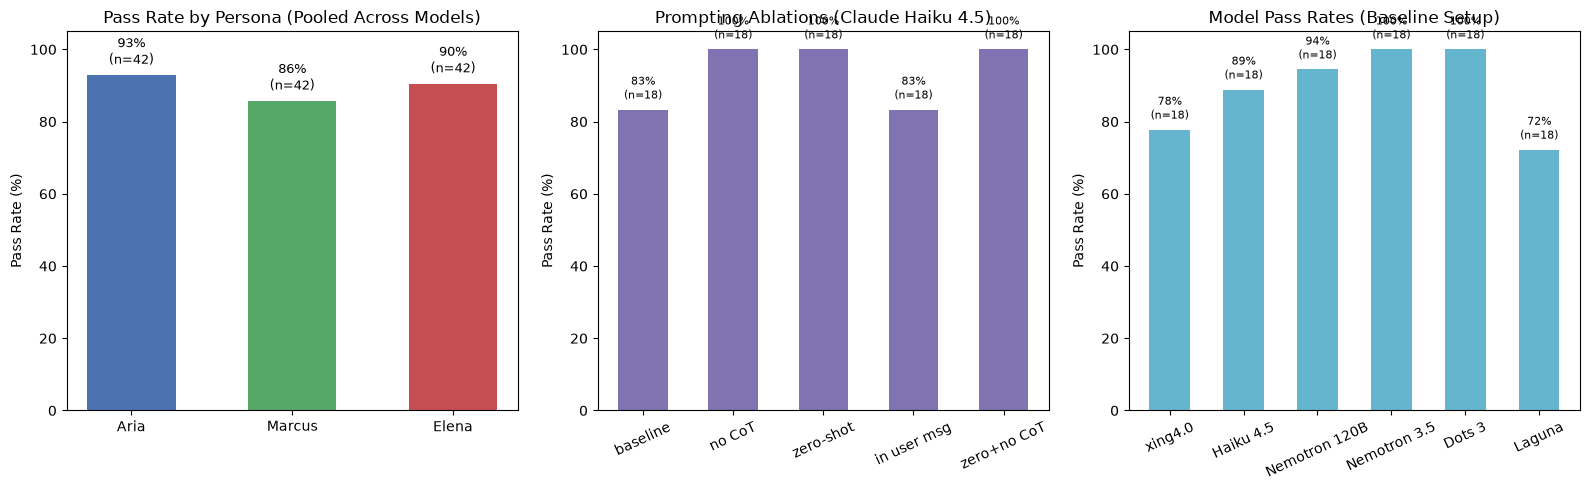

In [26]:
import matplotlib.pyplot as plt

def render_experiment_charts():
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # 1. Pass rate by persona (pooled across all models in personas + models suites)
    p_runs = [r for r in logged("personas") + logged("models") if not r["simulated"]]
    personas = ["friendly_advisor", "strict_auditor", "creative_curator"]
    labels = ["Aria", "Marcus", "Elena"]
    rates, ns = [], []
    for p in personas:
        subset = [r for r in p_runs if r.get("persona_key") == p or f"persona={p}" in r.get("condition", "")]
        passed = sum(r["metrics"]["passed"] for r in subset)
        rates.append(100 * passed / len(subset) if subset else 0)
        ns.append(len(subset))
    
    ax = axes[0]
    bars = ax.bar(labels, rates, color=["#4C72B0", "#55A868", "#C44E52"], width=0.55)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Pass Rate (%)")
    ax.set_title("Pass Rate by Persona (Pooled Across Models)")
    for bar, n, r in zip(bars, ns, rates):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"{r:.0f}%\n(n={n})", ha="center", va="bottom", fontsize=9)
        
    # 2. Prompting ablations (Claude Haiku 4.5 on Bedrock)
    ax = axes[1]
    haiku_prompt = logged("prompting", "c4_experiments_bedrock.jsonl")
    cond_order = ["baseline", "no CoT", "zero-shot", "in user msg", "zero+no CoT"]
    cond_keys = ["baseline (CoT, few-shot, system)", "no CoT", "zero-shot (no examples)", "instructions in user message", "zero-shot + no CoT"]
    h_rates, h_ns = [], []
    for ck in cond_keys:
        subset = [r for r in haiku_prompt if r["condition"] == ck]
        passed = sum(r["metrics"]["passed"] for r in subset)
        h_rates.append(100 * passed / len(subset) if subset else 0)
        h_ns.append(len(subset))
    bars = ax.bar(cond_order, h_rates, color="#8172B2", width=0.55)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Pass Rate (%)")
    ax.set_title("Prompting Ablations (Claude Haiku 4.5)")
    ax.tick_params(axis="x", rotation=25)
    for bar, n, r in zip(bars, h_ns, h_rates):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"{r:.0f}%\n(n={n})", ha="center", va="bottom", fontsize=8)

    # 3. Model comparison (identical baseline settings)
    ax = axes[2]
    all_runs = logged()
    models_to_check = [
        ("xing4.0", "xingchen-agi/xing4.0-29b-a4b:free"),
        ("Haiku 4.5", "us.anthropic.claude-haiku-4-5-20251001-v1:0"),
        ("Nemotron 120B", "nvidia/nemotron-3-super-120b-a12b:free"),
        ("Nemotron 3.5", "nvidia/nemotron-3.5-super-vl:free"),
        ("Dots 3", "dots-studio/dots-3-note-preview:free"),
        ("Laguna", "poolside/laguna-s-2.1:free"),
    ]
    m_labels, m_rates, m_ns = [], [], []
    for short_name, m_id in models_to_check:
        subset = [r for r in all_runs if r.get("model") == m_id and r["suite"] in ("personas", "models")]
        if subset:
            passed = sum(r["metrics"]["passed"] for r in subset)
            m_labels.append(short_name)
            m_rates.append(100 * passed / len(subset))
            m_ns.append(len(subset))
    bars = ax.bar(m_labels, m_rates, color="#64B5CD", width=0.55)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Pass Rate (%)")
    ax.set_title("Model Pass Rates (Baseline Setup)")
    ax.tick_params(axis="x", rotation=25)
    for bar, n, r in zip(bars, m_ns, m_rates):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"{r:.0f}%\n(n={n})", ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.show()

render_experiment_charts()


### 6.12 Persona fidelity (blind LLM judge)
Existing completed, error-free answers are judged by gpt-4o-mini; no agent is rerun. Persona names are replaced with [name].
The judge sees only the traveler question, anonymised answer and verbatim tone/task profiles in fixed A/B/C order; it identifies the profile and rates tone (1–5).
Three-way chance accuracy is 33.3%; a length-only rank baseline predicts shortest=Marcus, middle=Aria, longest=Elena within complete model/case/repeat triplets (ties break by persona key).
Set (a) compares the personas/models suites; set (b) compares Haiku Aria/Elena v1 versus v2. Errors are reported separately; small cells are descriptive.
Judge caveat: gpt-4o-mini wrote 18 source answers; the tables also exclude its answers. All analysis below reads the saved judge file offline.


In [27]:
from pathlib import Path
from IPython.display import display, Markdown
import pandas as pd
import experiments as exp

judge_summary = exp.summarize_persona_judge(
    exp.load_persona_judge_results(Path("logs/c4_persona_judge.jsonl")))
display(Markdown(f"Saved rows: {judge_summary['total_rows']}; judged: {judge_summary['judged']}; errors: {judge_summary['errors']}"))
for title, key in [("Overall (both sets)", "overall"),
                   ("Set (a): judge vs length vs chance", "accuracy"),
                   ("Set (a): true × predicted", "confusion_matrix"),
                   ("Set (a): mean tone match (1–5)", "tone_match"),
                   ("Set (b): Haiku v1 vs v2", "persona_v2"),
                   ("Set (a): excluding gpt-4o-mini", "excluding_gpt4o_mini"),
                   ("Both sets: excluding gpt-4o-mini", "overall_excluding_gpt4o_mini")]:
    display(Markdown("**" + title + "**"))
    value = judge_summary[key]
    display(pd.DataFrame([value] if isinstance(value, dict) else value))
display(Markdown(judge_summary["caveat"]))

# Optional offline heatmap; set True to display.
show_persona_heatmap = False
if show_persona_heatmap:
    import matplotlib.pyplot as plt
    matrix = pd.DataFrame(judge_summary["confusion_matrix"]).set_index("true_persona")
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(matrix.values, cmap="Blues")
    ax.set_xticks(range(3), matrix.columns, rotation=25, ha="right")
    ax.set_yticks(range(3), matrix.index)
    ax.set(xlabel="Predicted persona", ylabel="True persona", title="Blind persona identification: set (a)")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(matrix.iloc[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()


Saved rows: 181; judged: 181; errors: 0

**Overall (both sets)**

,n,correct,accuracy_pct
0,181,109,60.220994


**Set (a): judge vs length vs chance**

,model,n,correct,accuracy_pct,baseline_n,length_accuracy_pct,judge_on_baseline_pct,chance_pct,length_tied_answers
0,ALL (set a),121,70,57.851240,117,49.572650,57.264957,33.333333,12
1,dots-studio/dots-3-note-preview:free,18,7,38.888889,18,55.555556,38.888889,33.333333,6
2,gpt-4o-mini,18,9,50.000000,18,33.333333,50.000000,33.333333,3
3,nvidia/nemotron-3-super-120b-a12b:free,18,11,61.111111,18,61.111111,61.111111,33.333333,0
4,nvidia/nemotron-3.5-super-vl:free,18,10,55.555556,18,61.111111,55.555556,33.333333,0
5,poolside/laguna-s-2.1:free,15,9,60.000000,12,25.000000,58.333333,33.333333,3
6,us.anthropic.claude-haiku-4-5-20251001-v1:0,18,14,77.777778,18,72.222222,77.777778,33.333333,0
7,xingchen-agi/xing4.0-29b-a4b:free,16,10,62.500000,15,26.666667,60.000000,33.333333,0


...

**Set (a): excluding gpt-4o-mini**

,n,correct,accuracy_pct
0,103,61,59.223301


**Both sets: excluding gpt-4o-mini**

,n,correct,accuracy_pct
0,163,100,61.349693


gpt-4o-mini wrote 18 of the answers it judges. Fixed label order and a single judge can bias results; small cells are descriptive. Length baseline excludes incomplete triplets; ties use alphabetical persona keys. Tone means and confusion matrix use set (a); errors are excluded from accuracies.

## 7. Reflection Questions

All numbers below come from the logged runs in section 6 (497 error-free logged runs on 9 models, re-scored with the final scorer).

### Question 1: Which persona gave the most helpful or natural results?
**Answer:**
On correctness, the three personas were similar. With identical settings on seven models, Aria passed 39/42 runs, Marcus 36/42 and Elena 38/42. The real difference was style: Marcus answered in about 58 words with itemized figures, while Aria and Elena wrote about 91 words in a warmer, more descriptive voice.

For a customer-facing concierge, Aria felt the most natural. Her answers read like a travel agent talking to a client rather than an audit. But each persona failed in its own way:
* **Aria and Elena invented airfares.** On the flights question, Aria quoted a price range in 6 of 33 answers and Elena in 4 of 13. A typical one: *"Typical round-trip airfare to Rome… generally ranges from $600 to $1,200."* Marcus did this in 0 of 27 answers.
* **Marcus over-checked.** On xing4.0 he kept re-running policy lookups until he hit the step limit. On Haiku, he was the persona that re-added the guide fee and reported $5,100 instead of $4,700.

Two changes made the personas more useful together than apart:
* **Persona v2** added one boundary sentence to Aria and Elena ("for costs outside the catalog, such as flights, say WanderWise doesn't quote them"). Airfare quotes dropped from 4 of 10 to 0 of 10 on Haiku, and Elena passed the flights question 5 of 5. The side effect: Aria v2 twice answered without calling the policy tool, because her new wording already gave her the answer.
* **Automatic routing** sends price, policy and flight questions to Marcus, and experience questions to Elena. It passed 5/6, the same as Aria alone, but the flights question went to Marcus and got no invented price.

**A blind judge confirms the voices differ, but unevenly.** With persona names removed, `gpt-4o-mini` picked the right persona for 70 of 121 answers (57.9%; chance is 33.3%). On the same 117 answers with a length baseline, the judge scored 57.3%, compared with 49.6% for length. Marcus was the easiest to recognise (33 of 39, tone match 4.6/5). Elena was the hardest: 21 of her 40 answers were taken for Marcus (tone match 2.6/5), so her "vivid" instruction often didn't come through. Persona v2 made Aria more recognisable (73% → 93%) but Elena less (60% → 33%): the boundary that stopped her inventing airfares also flattened her voice. These are results from one judge with small cells, and `gpt-4o-mini` also wrote 18 of the answers it judged (excluding those gives 59%). *(§6.12)*

My conclusion: Aria is the best default voice, Marcus is the safest for prices and policies, and routing between them provides specialised voices, though its measured pass rate tied Aria alone (5/6).

### Question 2: Which prompt and configuration combination performed best for your use case?
**Answer:**
**The model mattered far more than the persona, the prompt style or the sampling settings.** With identical settings (3 personas × 6 cases):
* `dots-3-note-preview` 18/18 and `nemotron-3.5-super-vl` 18/18
* OpenAI `gpt-4o-mini` 17/18 and `nemotron-3-super-120b` 17/18
* Claude Haiku 4.5 16/18
* xing4.0 14/18
* `laguna-s-2.1` 13/18

Three free models and OpenAI's `gpt-4o-mini` matched or beat Haiku. `gpt-4o-mini` was also the fastest (about 3 seconds per answer) and the most concise (about 48 words).

**The same prompt change helped one model and hurt another:**
* **On xing4.0,** chain-of-thought plus few-shot examples helped. Runs with both passed 12/12, against 12/18 without (one-sided Fisher p = 0.03). All 6 failures without them were loops on the two policy questions.
* **On Haiku, it was the opposite.** With both, 30/36 passed; without, 54/54. All 6 failures were the same Swiss budget question: Haiku wrote $5,100 in 6 of 6 runs with both, and 0 of 9 without. I treat this as one case-specific failure rather than a general drop in quality. At temperature 0.1 the repeated runs are nearly identical (the no-CoT Swiss answer was word-for-word the same all three times), so they aren't independent samples.
* **System prompt vs instructions in the user message made no difference** on either model (6/6 vs 6/6 on xing4.0; 15/18 vs 15/18 on Haiku).

**No single sampling setting had a measurable effect at this sample size.** xing4.0's 60 parameter runs passed at 46/60 overall, and every condition was within two runs of that. On Haiku, several conditions were sent with exactly the same settings (Haiku ignores top-p and the penalties), yet they scored between 83% and 100%. That spread is the noise. The one clear effect was `max_tokens=120`: it cut answers from 135 to 43 words on Haiku, and from 78 to 52 on xing4.0, with no loss of correctness.

**Best combination for this use case:** a strong instruction-following model (`dots-3-note-preview` or `nemotron-3.5-super-vl`, or OpenAI `gpt-4o-mini` when speed matters), CoT and few-shot examples in the system prompt, the v2 personas, and automatic routing. On Haiku specifically, I would drop either CoT or the worked examples.

### Question 3: How well did your agent reason and use tools?
**Answer:**
Mostly well. Across 497 error-free logged runs, the agent called the required tools in 473 (95%), and took 2.8 steps on average. Badly formatted replies only came from `laguna-s-2.1` (22 of them); the other eight models had none. A typical good trace for a price question is `search_travel_packages` → `calculate_trip_budget` → Final Answer. For a question with no approved policy, it's `lookup_policy_rule` → `record_unanswered_inquiry` → Final Answer.

The failures fell into three patterns:
1. **Loops.** The model kept re-checking until the 5-step limit: 12 of xing4.0's 108 core runs. For example, on the flights question it alternated `lookup_policy_rule` and `search_travel_packages` four times. With loop guards on (repeat calls blocked, and one forced answer at the limit), xing4.0 passed 5/6 instead of 3/6 on the two policy questions. To be precise, the guards rescued one run: they blocked the repeated `lookup_policy_rule(topic='flights')` twice and then produced a forced answer. Another run passed without the guards doing anything, and one still failed.
2. **Answering without the tool.** In 4 xing4.0 runs, the agent told the traveler their question had been passed to "our guest-experience team" without calling `record_unanswered_inquiry`. `laguna-s-2.1` made up Bali totals ($4,400, $4,300) without calling the calculator.
3. **Not trusting the Observation.** In 12 runs (9 on Haiku, 3 on xing4.0), the calculator returned $4,700 for the Swiss trip, but the final answer said $5,100. The Thought just before it said *"I have the verified budget calculation from the tool"*, so the error happened while writing the final breakdown (adding the $400 guide fee a second time), not in the reasoning step.

Model size showed clearly too: a 2.6B model could not keep to the Thought/Action format at all during testing, while most larger models made no format errors; laguna-s-2.1 was the exception with 22.

### Question 4: Did your instructions block change the agent's behavior in a noticeable way? How?
**Answer:**
Yes, though how much depended on the model. I tested it three ways.

**Removing the rules.** I kept only the input/output format and the tool list, and dropped the operational rules and examples (on `dots-3-note-preview`). Correctness barely changed: 18/18 with rules vs 16/17 without (one run failed for an API error). But the only invented airfare in this test appeared without the rules (Elena: *"generally ranges from $600 to $1,200"*). Aria's answers also nearly doubled in length, from 76 to 141 words. On a strong model, the rules mainly controlled scope and length rather than whether it followed the process.

**Removing the worked examples.** On xing4.0, the examples were decisive: 16/18 passed with them, against 8/12 without. On the two policy questions it went from 4/6 to 0/4. The second example shows exactly the "look up the policy → nothing approved → log the question" path, and without it the model looped instead of logging. The examples also shaped wording: the 4 runs mentioned in Q3 copied the example's "passed your question to our guest-experience team" without doing the action. On Haiku, the examples weren't needed (36/36 without), and combined with CoT they coincided with the $5,100 error.

**The persona/instruction conflict.** The rule "never invent flight prices" competed with Aria's "share thoughtful travel inspiration" and Elena's "paint vivid pictures". `check_persona_conflicts()` flags exactly those phrases. Adding one boundary sentence to each persona (v2) took airfare quotes from 4/10 to 0/10 on Haiku, though the blind judge in §6.12 found Elena's voice harder to recognise afterwards, so the fix came at some cost to her persona.

Finally, the explicit output format ("one Thought line, then exactly one Action or Final Answer, never an Observation"), together with the parser and stop sequence, kept format errors at zero for eight of the nine models.

### Question 5: What were the biggest challenges in implementation?
**Answer:**
1. **Unreliable model providers.** The OpenAI key ran out of credits, `gemini-2.5-flash` was retired for new accounts, and its replacement allowed only 20 free requests a day. Free OpenRouter models were often overloaded (429 and 502 errors) or blocked for this kind of app. Worse, my first notebook run silently fell back to a canned simulator, so its "results" meant nothing. I changed the design so that a failed call is always reported as an error. I also added retries for per-minute limits, fail-fast for daily quotas, and a `--resume` option that re-runs only failed experiments.
2. **Every provider treats parameters differently.** Gemini 3.8 rejects penalties. Claude rejects top-p together with temperature, and any temperature above 1.0. OpenRouter silently drops whatever a model doesn't support. To keep comparisons honest, every run records which parameters were applied, ignored or adjusted.
3. **Parsing free-form ReAct output.** Models wrapped actions in markdown, put parentheses inside arguments, invented their own `Observation:` lines, and some "reasoning" models leaked hidden reasoning into the reply. I handled this with an AST-based argument parser, a stop sequence on `\nObservation:`, a format-retry edge in the graph, and turning off hidden reasoning where the provider allows it.
4. **Measuring fairly.** My first automatic scorer marked "No group tour is planned" as a hallucination, and missed a wrong "Grand Total" that came after a correct breakdown. I made it ignore negated phrases, re-scored every logged run, and checked each changed verdict by hand. The other lesson was statistical: with 6 runs per condition and near-identical repeats at low temperature, a one-run difference is noise. So I pooled conditions, reported exact counts, and avoided claiming effects the data doesn't support.

## 8. Interactive Gradio Demonstration
Launch the interactive web application to demo persona switching and inspect the live ReAct trace.

![C4 Gradio app](docs/c4_app_screenshot.png)


In [28]:
from c4_app import build_c4_demo
demo = build_c4_demo()
demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.
